# Final Comparison Notebook
### CSE 438 Part B — Label-Efficiency Comparison Across SSL Methods



In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


## Config 

In [2]:
PATHS = {
    "PartA_baseline": "/kaggle/input/notebooks/munemprionto/cse438-assignment-nb1/results.json",
    "SimCLR":  "/kaggle/input/notebooks/mashrur135/nb-simclr-downstream/simclr_results.json",
    "BYOL":    "/kaggle/input/notebooks/mashrur135/nb-byol-downstream/byol_results.json",
    "MAE":     "/kaggle/input/notebooks/mashrur135/nb-mae-downstream/mae_results.json",
    "DINOv2":  "/kaggle/input/notebooks/mashrur135/nb-dinov2-downstream/dinov2_results.json",
}


NUM_TRAIN_IMAGES_PART_A = 280  

CLASS_NAMES = None   


## Load Part A's baseline result

In [3]:
with open(PATHS["PartA_baseline"]) as f:
    part_a_all = json.load(f)

part_a = part_a_all["DeepLabV3-ResNet50"]
print("Part A (fully supervised) baseline:")
print(json.dumps(part_a, indent=2))


Part A (fully supervised) baseline:
{
  "mIoU": 0.5531670147987703,
  "pixel_accuracy": 0.8521180470784505,
  "mean_pixel_accuracy": 0.7939560143549981,
  "dice_coefficient": 0.6758107791661795,
  "best_validation_mIoU": 0.5181508628592699,
  "training_time_minutes": 108.76786950031916,
  "epochs_trained": 50,
  "per_class_iou": {
    "unlabeled": 0.06123346056687551,
    "paved-area": 0.8542554124393854,
    "dirt": 0.510946516569195,
    "grass": 0.8938308989653158,
    "gravel": 0.6925799552218374,
    "water": 0.881332479238427,
    "rocks": 0.47245489462420454,
    "pool": 0.8664930900775502,
    "vegetation": 0.5884464548111281,
    "roof": 0.802569677097441,
    "wall": 0.48446452464304696,
    "window": 0.568793130489335,
    "door": 0.14140027456363993,
    "fence": 0.3061144090180594,
    "fence-pole": 0.1272847182965894,
    "person": 0.5554302866662837,
    "dog": 0.2280986372485399,
    "car": 0.845888423089326,
    "bicycle": 0.4575748852803224,
    "tree": 0.538770739397

## Load each SSL method's Task E result

In [4]:
ssl_results = {}
for method in ["SimCLR", "BYOL", "MAE", "DINOv2"]:
    with open(PATHS[method]) as f:
        ssl_results[method] = json.load(f)

for method, res in ssl_results.items():
    print(f"--- {method} ---")
    print(f"  test mIoU: {res['test_mIoU']:.4f} | Dice: {res['test_mean_dice']:.4f} | "
          f"Pixel Acc: {res['test_pixel_accuracy']:.4f} | "
          f"labelled images used: {res['num_labelled_finetune_images']} | "
          f"frozen encoder: {res['freeze_encoder']}")


--- SimCLR ---
  test mIoU: 0.2907 | Dice: 0.4133 | Pixel Acc: 0.6218 | labelled images used: 60 | frozen encoder: True
--- BYOL ---
  test mIoU: 0.2497 | Dice: 0.3643 | Pixel Acc: 0.5788 | labelled images used: 60 | frozen encoder: True
--- MAE ---
  test mIoU: 0.0474 | Dice: 0.0809 | Pixel Acc: 0.2261 | labelled images used: 60 | frozen encoder: True
--- DINOv2 ---
  test mIoU: 0.0809 | Dice: 0.1322 | Pixel Acc: 0.3011 | labelled images used: 60 | frozen encoder: True


## Consolidated metrics table (Task E requirement)

In [5]:
rows = []
rows.append({
    "Model": "DeepLabV3-ResNet50 (Part A, fully supervised)",
    "mIoU": part_a["mIoU"],
    "Pixel Accuracy": part_a["pixel_accuracy"],
    "Dice": part_a["dice_coefficient"],
    "Labelled Images Used": NUM_TRAIN_IMAGES_PART_A,
    "Frozen Encoder": "N/A (fully supervised)",
})

for method, res in ssl_results.items():
    rows.append({
        "Model": method,
        "mIoU": res["test_mIoU"],
        "Pixel Accuracy": res["test_pixel_accuracy"],
        "Dice": res["test_mean_dice"],
        "Labelled Images Used": res["num_labelled_finetune_images"],
        "Frozen Encoder": res["freeze_encoder"],
    })

comparison_df = pd.DataFrame(rows)
comparison_df = comparison_df.sort_values("mIoU", ascending=False).reset_index(drop=True)
comparison_df


,Model,mIoU,Pixel Accuracy,Dice,Labelled Images Used,Frozen Encoder
0,"DeepLabV3-ResNet50 (Part A, fully supervised)",0.553167,0.852118,0.675811,280,N/A (fully supervised)
1,SimCLR,0.290742,0.621757,0.413306,60,True
2,BYOL,0.249659,0.578787,0.364296,60,True
3,DINOv2,0.080884,0.301131,0.132196,60,True
4,MAE,0.047440,0.226074,0.080890,60,True


## Label-efficiency table — the central question of Part B

For each SSL method: what fraction of Part A's mIoU is recovered, using what
fraction of Part A's labelled images? State the exact label-count ratio, as
required by Section 6.8 of the report.

In [6]:
label_efficiency_rows = []
for method, res in ssl_results.items():
    labelled_used = res["num_labelled_finetune_images"]
    label_ratio = labelled_used / NUM_TRAIN_IMAGES_PART_A
    miou_recovered_pct = (res["test_mIoU"] / part_a["mIoU"]) * 100

    label_efficiency_rows.append({
        "Method": method,
        "Labelled Images Used": labelled_used,
        "Part A Labelled Images": NUM_TRAIN_IMAGES_PART_A,
        "Label Ratio": f"{label_ratio:.1%}",
        "Test mIoU": res["test_mIoU"],
        "Part A mIoU": part_a["mIoU"],
        "% of Full-Supervision mIoU Recovered": round(miou_recovered_pct, 1),
    })

label_efficiency_df = pd.DataFrame(label_efficiency_rows)
label_efficiency_df = label_efficiency_df.sort_values(
    "% of Full-Supervision mIoU Recovered", ascending=False).reset_index(drop=True)

print("=" * 70)
print("LABEL-EFFICIENCY RANKING")
print("=" * 70)
label_efficiency_df


LABEL-EFFICIENCY RANKING


,Method,Labelled Images Used,Part A Labelled Images,Label Ratio,Test mIoU,Part A mIoU,% of Full-Supervision mIoU Recovered
0,SimCLR,60,280,21.4%,0.290742,0.553167,52.6
1,BYOL,60,280,21.4%,0.249659,0.553167,45.1
2,DINOv2,60,280,21.4%,0.080884,0.553167,14.6
3,MAE,60,280,21.4%,0.047440,0.553167,8.6


## mIoU comparison chart

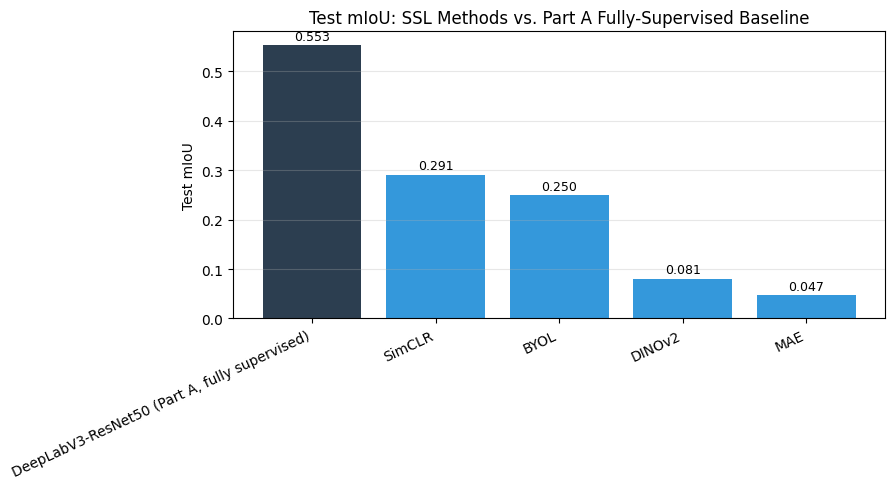

In [7]:
plt.figure(figsize=(9, 5))
colors = ["#2c3e50" if "Part A" in m else "#3498db" for m in comparison_df["Model"]]
bars = plt.bar(comparison_df["Model"], comparison_df["mIoU"], color=colors)
plt.ylabel("Test mIoU")
plt.title("Test mIoU: SSL Methods vs. Part A Fully-Supervised Baseline")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)

for bar, val in zip(bars, comparison_df["mIoU"]):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.005, f"{val:.3f}",
              ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig("/kaggle/working/miou_comparison_chart.png", dpi=150, bbox_inches="tight")
plt.show()


## Label-efficiency scatter: labelled images used vs. mIoU recovered

This is the chart that visually answers the assignment's central question —
methods toward the top-left recover the most performance with the fewest
labels.

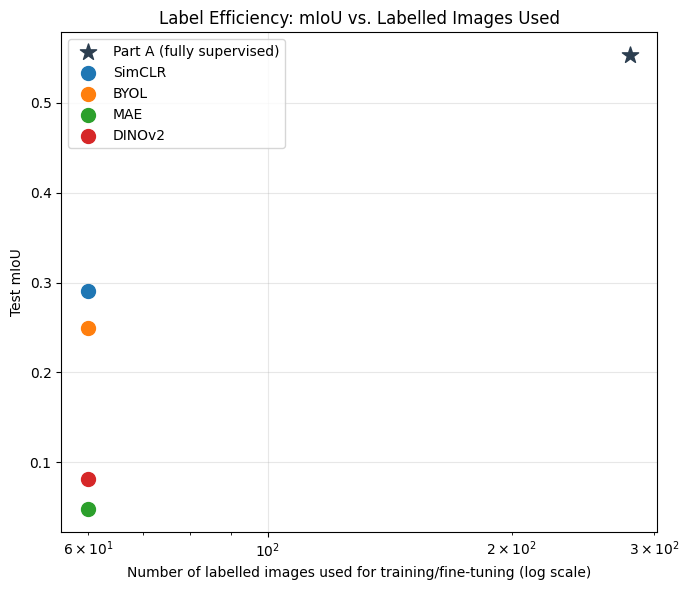

In [8]:
plt.figure(figsize=(7, 6))

# Part A reference point
plt.scatter([NUM_TRAIN_IMAGES_PART_A], [part_a["mIoU"]], s=150, marker="*",
            color="#2c3e50", label="Part A (fully supervised)", zorder=5)

for method, res in ssl_results.items():
    plt.scatter(res["num_labelled_finetune_images"], res["test_mIoU"], s=100, label=method)

plt.xlabel("Number of labelled images used for training/fine-tuning (log scale)")
plt.ylabel("Test mIoU")
plt.xscale("log")
plt.title("Label Efficiency: mIoU vs. Labelled Images Used")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/label_efficiency_scatter.png", dpi=150, bbox_inches="tight")
plt.show()


## Per-class IoU comparison across all 4 models



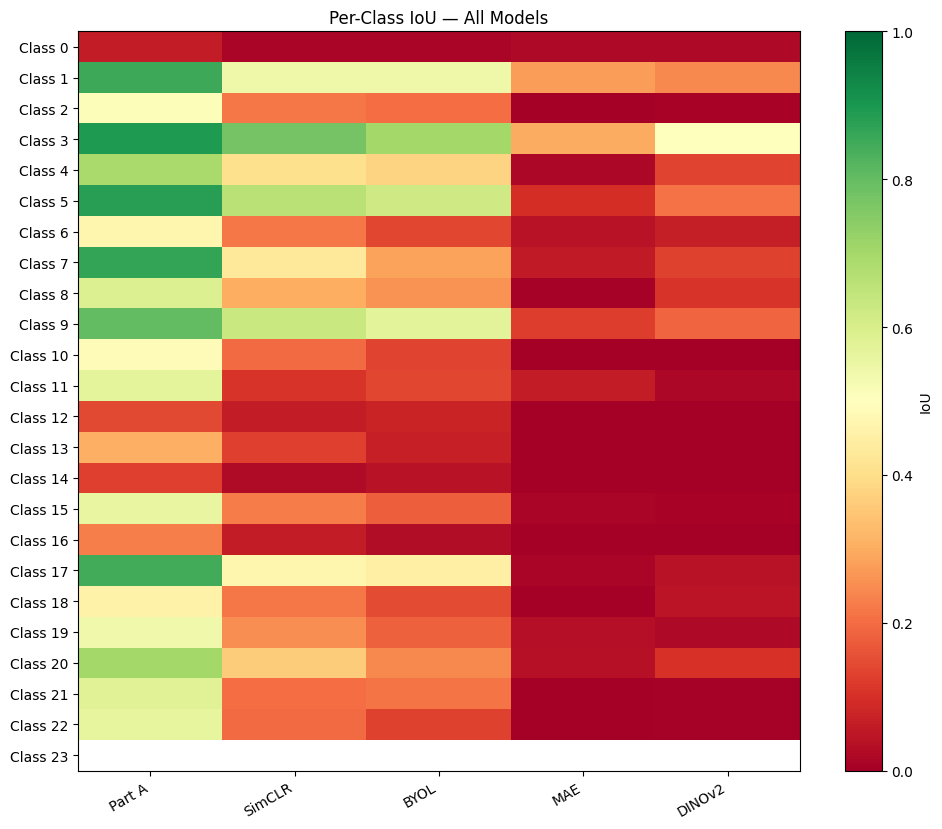

,Part A,SimCLR,BYOL,MAE,DINOv2
Class 0,0.061233,0.013647,0.015068,0.021221,0.023397
Class 1,0.854255,0.542686,0.540289,0.274257,0.245073
Class 2,0.510947,0.215538,0.201722,0.000000,0.010637
Class 3,0.893831,0.773904,0.699657,0.298766,0.498703
Class 4,0.692580,0.402573,0.378397,0.016991,0.133940
Class 5,0.881332,0.663139,0.618386,0.095196,0.207468
Class 6,0.472455,0.218534,0.139105,0.042091,0.063476
Class 7,0.866493,0.425878,0.284527,0.054695,0.131644
Class 8,0.588446,0.302337,0.259002,0.005301,0.106571
Class 9,0.802570,0.629881,0.571841,0.122523,0.190335


In [9]:
num_classes = len(ssl_results["SimCLR"]["per_class_iou"])
class_labels = CLASS_NAMES if CLASS_NAMES else [f"Class {i}" for i in range(num_classes)]

per_class_matrix = pd.DataFrame({
    "Part A": list(part_a["per_class_iou"].values()) if isinstance(part_a["per_class_iou"], dict)
              else part_a["per_class_iou"],
})
for method, res in ssl_results.items():
    per_class_matrix[method] = res["per_class_iou"]

per_class_matrix.index = class_labels

plt.figure(figsize=(10, max(6, num_classes * 0.35)))
plt.imshow(per_class_matrix.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
plt.colorbar(label="IoU")
plt.xticks(range(len(per_class_matrix.columns)), per_class_matrix.columns, rotation=30, ha="right")
plt.yticks(range(len(per_class_matrix.index)), per_class_matrix.index)
plt.title("Per-Class IoU — All Models")
plt.tight_layout()
plt.savefig("/kaggle/working/per_class_iou_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

per_class_matrix


## Save consolidated results for the report

In [10]:
comparison_df.to_csv("/kaggle/working/final_comparison_table.csv", index=False)
label_efficiency_df.to_csv("/kaggle/working/label_efficiency_table.csv", index=False)
per_class_matrix.to_csv("/kaggle/working/per_class_iou_comparison.csv")

print("Saved:")
print("  final_comparison_table.csv")
print("  label_efficiency_table.csv")
print("  per_class_iou_comparison.csv")
print("  miou_comparison_chart.png")


Saved:
  final_comparison_table.csv
  label_efficiency_table.csv
  per_class_iou_comparison.csv
  miou_comparison_chart.png


## Discussion prompts for Section 6.8 / 6.9 (fill in after seeing your real numbers)

- Which SSL method closes the gap to full supervision **best**, and with how
  much less labelled data specifically (state the exact ratio)?
- Does a contrastive method (SimCLR/BYOL) or a self-distillation/reconstruction
  method (DINOv2/MAE) transfer better for THIS aerial dataset? Any hypothesis
  tied to your dataset's visual structure (e.g. repetitive textures, small
  objects, top-down viewpoint)?
- Did frozen vs. fine-tuned encoder (tested in Task C/D for at least one
  method) make a bigger difference than which SSL method was used at all?
- Any result that surprised you — a method performing worse/better than
  expected — and your best explanation?